# Hipótesis univariada: fumadores de cigarrillo adultos

## Carga de datos

In [1]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt

data = pd.read_csv("CKD-NHANES/CKD_NHANES_2021_2023.csv", sep = ",", encoding = "latin1", on_bad_lines= "skip")
pd.set_option("display.max_columns", None)
data.head()

,participant_id,age,gender,ethnicity,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,bp_diastolic,serum_creatinine,blood_urea_nitrogen,albumin_serum,phosphorus,bicarbonate,calcium,uric_acid,urine_creatinine,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_stage,ckd_present
0,130378.0,43.0,Male,Non-Hispanic Asian,5.0,5.00,27.0,86.9,179.5,135.0,98.0,0.80,11.0,4.3,3.7,24.0,9.6,5.1,136.0,23.12,17.00,2.0,NaN,NaN,1.0,3.0,112.61,No CKD,0
1,130379.0,66.0,Male,Non-Hispanic White,5.0,5.00,33.5,101.8,174.2,121.0,84.0,0.79,24.0,3.9,3.2,25.0,9.4,8.5,64.0,4.25,6.64,2.0,NaN,NaN,1.0,3.0,97.98,No CKD,0
2,130380.0,44.0,Female,Other Hispanic,3.0,1.41,29.7,69.4,152.9,111.0,79.0,0.64,10.0,3.7,3.8,25.0,9.4,4.4,157.0,12.43,7.92,1.0,2.0,1.0,2.0,NaN,111.69,No CKD,0
3,130381.0,5.0,Female,Other/Multiracial,NaN,1.53,23.8,34.3,120.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,208.0,16.12,7.75,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1
4,130382.0,2.0,Male,Non-Hispanic White,NaN,3.60,NaN,13.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1


## Limpieza de datos

### Conversión de columnas a enteros

Estas columnas se guardan como decimales en el archivo, pero sus valores son enteros: códigos de categorías (educación, diabetes, tabaquismo), identificadores, edad o mediciones sin decimales. Se redondean y se pasan a `Int64`, el tipo entero de pandas que admite valores nulos.

In [3]:
columnas_enteras = ["participant_id", "age", "education_level", "bp_systolic", "bp_diastolic",
                    "blood_urea_nitrogen", "bicarbonate", "urine_creatinine", "diabetes_diagnosed",
                    "insulin_use", "diabetes_pills", "ever_smoked", "current_smoker", "ckd_present"]

data[columnas_enteras] = data[columnas_enteras].round().astype("Int64")

### Códigos de falta de respuesta (7 y 9)

Según la metadata, en las variables de cuestionario el **7** significa "se negó a responder" y el **9** "no sabe". No son categorías reales, así que se reemplazan por valores nulos (`NaN`) para que no se cuenten como respuestas.

In [4]:
columnas_cuestionario = ["education_level", "diabetes_diagnosed", "diabetes_pills", "ever_smoked", "current_smoker"]

for columna in columnas_cuestionario:
    data[columna] = data[columna].replace([7, 9], np.nan)

data[columnas_cuestionario].isna().sum()

education_level       4150
diabetes_diagnosed     197
diabetes_pills        9659
ever_smoked           3812
current_smoker        8690
dtype: int64

### Verificación: diabetes vs medicación

Se revisa si hay personas sin diabetes diagnosticada (`diabetes_diagnosed == 2`) que usan insulina o pastillas para la diabetes.

In [5]:
sin_diabetes = data["diabetes_diagnosed"] == 2
con_insulina = data["insulin_use"] == 1
con_pastillas = data["diabetes_pills"] == 1

print(f"Sin diabetes y con insulina: {(sin_diabetes & con_insulina).sum()}")
print(f"Sin diabetes y con pastillas: {(sin_diabetes & con_pastillas).sum()}")
print(f"Sin diabetes y con insulina o pastillas: {(sin_diabetes & (con_insulina | con_pastillas)).sum()}")

Sin diabetes y con insulina: 0
Sin diabetes y con pastillas: 60
Sin diabetes y con insulina o pastillas: 60


Nadie sin diagnóstico usa insulina. Hay 60 personas sin diagnóstico que toman pastillas, pero estas pastillas no indican necesariamente que la persona tenga diabetes: también se recetan, por ejemplo, en casos de prediabetes. Por eso esos registros no se modifican.

## Análisis de la hipótesis univariada

### Planteo de la hipótesis

**Hipótesis:** el porcentaje de fumadores actuales de cigarrillo entre los adultos del dataset (NHANES 2021-2023) **supera** el porcentaje de fumadores adultos de EE.UU. informado por el CDC.

**Valor de referencia:** según el CDC (Centros para el Control y la Prevención de Enfermedades), el **11,5 %** de los adultos (≥ 18 años) de EE.UU. fumaba cigarrillos en 2021.

Planteo de las hipótesis:
- **H0:** p = 0.115 (el porcentaje de fumadores del dataset es igual al de EE.UU.)
- **H1:** p > 0.115 (el porcentaje de fumadores del dataset supera al de EE.UU.)
- **Nivel de significancia:** α = 0.05

### Población observada

Se toman los adultos que respondieron válidamente `ever_smoked` (1 o 2). La pregunta solo se hizo a mayores de 18 años.

Se crea la variable `fumador`, que vale **1** si la persona fuma actualmente y **0** si no. El promedio de esta variable es la proporción de fumadores.

In [6]:
alpha = 0.05
p0 = 0.115

poblacion_observada = data[data["ever_smoked"].isin([1, 2])]
n_total_observados = len(poblacion_observada)

fumador = poblacion_observada["current_smoker"].isin([1, 2]).astype(int)
total_fumadores_activos = fumador.sum()
no_fumadores_total = n_total_observados - total_fumadores_activos

proporcion_de_fumadores = fumador.mean()
porcentaje_de_fumadores = proporcion_de_fumadores * 100

print(f"Edad mínima de la población observada: {poblacion_observada['age'].min():.0f} años")
print(f"Total de población adulta observada: {n_total_observados}")
print(f"Total de fumadores activos: {total_fumadores_activos}")
print(f"Total de personas que no fuman actualmente: {no_fumadores_total}")
print(f"Porcentaje de fumadores activos: {porcentaje_de_fumadores:.2f}%")
print(f"Porcentaje de referencia (CDC, EE.UU.): {p0 * 100:.1f}%")

Edad mínima de la población observada: 18 años
Total de población adulta observada: 8121
Total de fumadores activos: 1190
Total de personas que no fuman actualmente: 6931
Porcentaje de fumadores activos: 14.65%
Porcentaje de referencia (CDC, EE.UU.): 11.5%


### Test t para una muestra

Se usa el **test t para una muestra**, que compara la media de una variable contra un valor fijo. Como `fumador` vale 0 o 1, su media es la proporción de fumadores.

**Supuestos:**
- **Independencia:** cada fila es una persona distinta.
- **Normalidad:** una variable 0/1 no es normal, así que no tiene sentido aplicarle Shapiro-Wilk. El test igual es válido porque lo que se compara es la **media**, y con una muestra grande (n = 8121, muy por encima de 30) la media se distribuye aproximadamente normal (teorema central del límite).
- **Homocedasticidad:** no corresponde, porque hay un solo grupo y no hay varianzas que comparar.

Se usa `alternative="greater"` porque H1 dice que la proporción es **mayor** a 0.115 (test unilateral).

In [7]:
resultado = stats.ttest_1samp(fumador, popmean=p0, alternative="greater")

t_estadistico = resultado.statistic
p_valor = resultado.pvalue
grados_libertad = resultado.df
limite_inferior = resultado.confidence_interval(confidence_level=0.95).low

print(f"Estadístico t: {t_estadistico:.4f}")
print(f"Valor p: {p_valor:.4e}")
print(f"Grados de libertad: {grados_libertad}")
print(f"Límite inferior del IC 95% (unilateral): {limite_inferior * 100:.2f}%")

if p_valor < alpha:
    print("Se RECHAZA la hipótesis nula (H0). El porcentaje de fumadores activos es significativamente mayor al 11,5%.")
else:
    print("NO se rechaza la hipótesis nula (H0). No hay evidencia suficiente para afirmar que es mayor al 11,5%.")

Estadístico t: 8.0351
Valor p: 5.3331e-16
Grados de libertad: 8120
Límite inferior del IC 95% (unilateral): 14.01%
Se RECHAZA la hipótesis nula (H0). El porcentaje de fumadores activos es significativamente mayor al 11,5%.


#### Qué representa cada valor que devuelve el test

- **Estadístico t:** cuántos errores estándar está la proporción del dataset por encima (+) o por debajo (−) del 11,5 %. Se calcula como (proporción observada − 0.115) / (desvío / √n). Un valor cercano a 0 indica que el dato es parecido a la referencia. Un valor grande y positivo indica que el dato está bien por encima.
- **Valor p:** la probabilidad de obtener una proporción tan alta como la observada (o más alta) **si H0 fuera cierta**, es decir, si en realidad fumara el 11,5 %. Si es menor a α = 0.05, el resultado es muy difícil de explicar por azar y se rechaza H0.
- **Grados de libertad (n − 1):** definen qué distribución t se usa para calcular el p-valor. Con n tan grande, la distribución t es prácticamente igual a una normal.
- **Límite inferior del IC 95 %:** como el test es unilateral ("mayor que"), el intervalo es de la forma [límite inferior, ∞). Se lee así: con un 95 % de confianza, el porcentaje real de fumadores de la población es **al menos** ese valor. Si ese límite queda por encima de 11,5 %, la conclusión coincide con la del p-valor.

### Gráfico: proporción del dataset

Usamos un **gráfico de barras**, que sirve para comparar valores entre categorías:
- **Barra azul:** porcentaje de fumadores del dataset, con su intervalo de confianza del 95 % como barra de error (la "rayita" negra).
- **Barra gris:** porcentaje de referencia del CDC.
- **Línea roja punteada:** el valor de H0 (11,5 %).

**Cómo se interpreta:** si toda la barra de error de la barra azul queda por encima de la línea roja, la diferencia no se explica por el azar del muestreo. Eso coincide con rechazar H0. Si la barra de error tocara o cruzara la línea, no habría evidencia suficiente.

Para la barra de error se usa el intervalo de confianza **bilateral** del 95 % (proporción ± margen), que es el que se grafica habitualmente.

IC 95% bilateral: [13.88%, 15.42%]


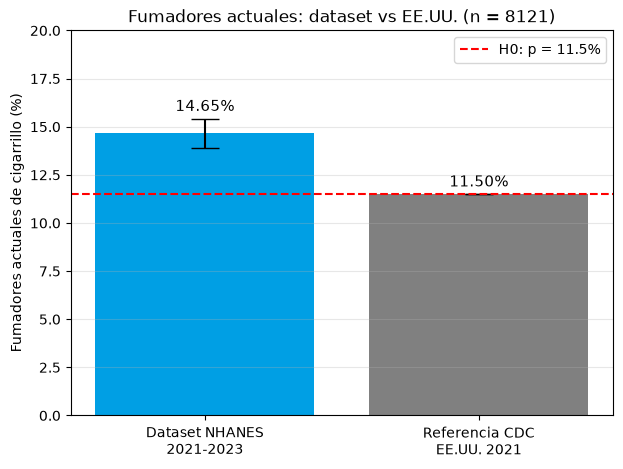

In [8]:
ic_bilateral = stats.ttest_1samp(fumador, popmean=p0).confidence_interval(confidence_level=0.95)
error_inferior = (proporcion_de_fumadores - ic_bilateral.low) * 100
error_superior = (ic_bilateral.high - proporcion_de_fumadores) * 100

print(f"IC 95% bilateral: [{ic_bilateral.low * 100:.2f}%, {ic_bilateral.high * 100:.2f}%]")

categorias = ["Dataset NHANES\n2021-2023", "Referencia CDC\nEE.UU. 2021"]
valores = [porcentaje_de_fumadores, p0 * 100]

plt.figure(figsize=(7, 7))
plt.bar(categorias, valores, color=["#009FE4", "gray"],
        yerr=[[error_inferior, 0], [error_superior, 0]], capsize=10)
plt.axhline(p0 * 100, color="red", linestyle="--", label=f"H0: p = {p0 * 100:.1f}%")

plt.text(0, porcentaje_de_fumadores + error_superior + 0.4, f"{porcentaje_de_fumadores:.2f}%", ha="center", fontsize=11)
plt.text(1, p0 * 100 + 0.4, f"{p0 * 100:.2f}%", ha="center", fontsize=11)

plt.ylabel("Fumadores actuales de cigarrillo (%)")
plt.title(f"Fumadores actuales: dataset vs EE.UU. (n = {n_total_observados})")
plt.ylim(0, 20)
plt.legend()
plt.grid(True, axis="y", alpha=0.3)
plt.show()

### Conclusión

El porcentaje de fumadores actuales de cigarrillo en los adultos del dataset es **14,65 %** (IC 95 %: 13,88 % – 15,42 %). Es mayor al 11,5 % que informa el CDC para EE.UU. en 2021.

El test t para una muestra da un p-valor muy menor a α = 0.05, por lo que **se rechaza H0**: el porcentaje de fumadores del dataset supera significativamente la cifra nacional. El gráfico lo confirma, porque el intervalo de confianza de la barra del dataset queda completo por encima de la línea del 11,5 %.